# Zameen.com Property Models

In this notebook I clean the zameen.com data and train models to predict property prices.
I will also check for underfitting and overfitting, and use GridSearchCV and log prices to fix them.

## Step 1: Import the basic tools
First I import the basic tools. `os` builds the file path, and `pandas`, `numpy` and `matplotlib` work with tables, numbers and charts.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
print('Basic tools imported')

Basic tools imported


## Step 2: Import the data tools and the scores
Now I import `train_test_split`, `StandardScaler`, `PolynomialFeatures`, `GridSearchCV` and the scores.

In [2]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score
print('Data tools and scores are ready')

Data tools and scores are ready


## Step 3: Import the regression models
Here I import the regression models from scikit-learn. I add Ridge for the polynomial regression fix.

In [3]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
print('Regression models are ready')

Regression models are ready


## Step 4: Import the classification models
Now I import the four classification models.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
print('Classification models are ready')

Classification models are ready


## Step 5: Load the data file
The file is inside the Dataset folder and its name is `zameenData (1).csv`.

In [5]:
data_path = os.path.join('Dataset', 'zameenData (1).csv')
df = pd.read_csv(data_path)
print('Data loaded. Rows and columns:', df.shape)

Data loaded. Rows and columns: (20571, 11)


## Step 6: Look at the first rows
`df.head()` shows the first five rows.

In [6]:
df.head()

,Unnamed: 0,agent,name,land_type,price,location,baths,area,pupose,bed,added_days
0,0,M A Associates,Muhammad Arshad,House,PKR25 Crore,"Garden Town, Lahore, Punjab",6,2 Kanal,For Sale,7,2 weeks ago
1,1,M A Associates,Muhammad Arshad,Commercial Plot,PKR60 Crore,"Gulberg, Lahore, Punjab",-,2 Kanal,For Sale,-,2 weeks ago
2,2,M A Associates,Muhammad Arshad,House,PKR15 Crore,"Gulberg, Lahore, Punjab",6,1 Kanal,For Sale,5,2 weeks ago
3,3,M A Associates,Muhammad Arshad,Commercial Plot,PKR25.5 Crore,"Wahdat Road, Lahore, Punjab",-,5.4 Kanal,For Sale,-,3 days ago
4,4,M A Associates,Muhammad Arshad,Residential Plot,PKR7.25 Crore,"Garden Town, Lahore, Punjab",-,1 Kanal,For Sale,-,2 weeks ago


## Step 7: Check the size and the types
I check the number of rows, columns, and data types.

In [7]:
print('Shape:', df.shape)
df.info()

Shape: (20571, 11)
<class 'pandas.DataFrame'>
RangeIndex: 20571 entries, 0 to 20570
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  20571 non-null  int64
 1   agent       16521 non-null  str  
 2   name        16507 non-null  str  
 3   land_type   20558 non-null  str  
 4   price       20558 non-null  str  
 5   location    20558 non-null  str  
 6   baths       20558 non-null  str  
 7   area        20558 non-null  str  
 8   pupose      20558 non-null  str  
 9   bed         20558 non-null  str  
 10  added_days  20558 non-null  str  
dtypes: int64(1), str(10)
memory usage: 3.9 MB


## Step 8: Drop the empty rows
Some rows are completely empty. I remove them.

In [8]:
df = df.dropna(how='all')
print('Shape after dropping empty rows:', df.shape)

Shape after dropping empty rows: (20571, 11)


## Step 9: Drop the useless columns
I drop columns that do not help to predict the price.

In [9]:
df = df.drop(columns=['Unnamed: 0', 'agent', 'name', 'added_days'])
print(df.columns.tolist())

['land_type', 'price', 'location', 'baths', 'area', 'pupose', 'bed']


## Step 10: Keep the good pupose rows
I keep only rows where the purpose is `For Sale` or `For Rent`.

In [10]:
df = df[df['pupose'].isin(['For Sale', 'For Rent'])]
print('Shape after keeping good pupose rows:', df.shape)

Shape after keeping good pupose rows: (20341, 7)


## Step 11: Drop the shifted rows
I drop any row where `baths` contains `PKR` because the data is shifted.

In [11]:
df = df[~df['baths'].astype(str).str.contains('PKR')]
print('Shape after dropping shifted rows:', df.shape)

Shape after dropping shifted rows: (20341, 7)


## Step 12: Fix the bed and baths columns
I change `-` to 0 and turn both columns into numbers.

In [12]:
df['bed_num'] = pd.to_numeric(df['bed'].replace('-', 0), errors='coerce')
df['baths_num'] = pd.to_numeric(df['baths'].replace('-', 0), errors='coerce')
print(df[['bed_num', 'baths_num']].head())

   bed_num  baths_num
0        7          6
1        0          0
2        5          6
3        0          0
4        0          0


## Step 13: Turn the price text into a number
I remove `PKR`, split the number, and multiply by the unit value.

In [13]:
df['price'] = df['price'].str.replace('PKR', '', regex=False)
price_parts = df['price'].str.split(' ', n=1, expand=True)
unit_map = {'Thousand': 1000, 'Lakh': 100000, 'Crore': 10000000, 'Arab': 1000000000}
df['price_num'] = pd.to_numeric(price_parts[0], errors='coerce') * price_parts[1].map(unit_map)
print(df['price_num'].head())

0    250000000.0
1    600000000.0
2    150000000.0
3    255000000.0
4     72500000.0
Name: price_num, dtype: float64


## Step 14: Drop the rows where area is in Months
I keep only rows whose area unit is `Kanal` or `Marla`.

In [14]:
area_parts = df['area'].str.split(' ', n=1, expand=True)
df = df[area_parts[1].isin(['Kanal', 'Marla'])]
print('Shape after dropping Months rows:', df.shape)

Shape after dropping Months rows: (20325, 10)


## Step 15: Convert the area to Marla
I turn `area` into Marla (1 Kanal = 20 Marla).

In [15]:
area_parts = df['area'].str.split(' ', n=1, expand=True)
area_num = pd.to_numeric(area_parts[0], errors='coerce')
df['area_marla'] = np.where(area_parts[1] == 'Kanal', area_num * 20, area_num)
print(df['area_marla'].head())

0     40.0
1     40.0
2     20.0
3    108.0
4     20.0
Name: area_marla, dtype: float64


## Step 16: Simplify the location
I take the first part of the location, keep the top 15, and call the rest `Other`.

In [16]:
df['area_name'] = df['location'].str.split(',').str[0]
top_areas = df['area_name'].value_counts().head(15).index
df['area_name'] = np.where(df['area_name'].isin(top_areas), df['area_name'], 'Other')
print(df['area_name'].value_counts().head())

area_name
Other           8221
DHA Defence     4103
Bahria Town     1538
Raiwind Road     973
Gulberg          730
Name: count, dtype: int64


## Step 17: Keep only For Sale rows
I keep only the `For Sale` rows for the models.

In [17]:
df = df[df['pupose'] == 'For Sale']
print('Shape after keeping For Sale rows:', df.shape)

Shape after keeping For Sale rows: (11927, 12)


## Step 18: Remove the outliers
I remove the top 1 percent of prices.

In [18]:
price_cut = df['price_num'].quantile(0.99)
df = df[df['price_num'] < price_cut]
print('Shape after removing price outliers:', df.shape)

Shape after removing price outliers: (11806, 12)


## Step 19: Drop rows with missing values
I drop rows that have NaN in the important columns.

In [19]:
df = df.dropna(subset=['price_num', 'area_marla', 'bed_num', 'baths_num'])
print('Shape after dropping NaNs:', df.shape)

Shape after dropping NaNs: (11806, 12)


## Step 20: Make dummy columns
I change the text columns `land_type` and `area_name` into 0 and 1 columns.

In [20]:
df = pd.get_dummies(df, columns=['land_type', 'area_name'], dtype=int)
print(df.columns.tolist())

['price', 'location', 'baths', 'area', 'pupose', 'bed', 'bed_num', 'baths_num', 'price_num', 'area_marla', 'land_type_Agricultural Land', 'land_type_Building', 'land_type_Commercial Plot', 'land_type_Factory', 'land_type_Farm House', 'land_type_Flat', 'land_type_House', 'land_type_Industrial Land', 'land_type_Lower Portion', 'land_type_Office', 'land_type_Penthouse', 'land_type_Plot File', 'land_type_Plot Form', 'land_type_Residential Plot', 'land_type_Room', 'land_type_Shop', 'land_type_Upper Portion', 'land_type_Warehouse', 'area_name_Allama Iqbal Town', 'area_name_Askari', 'area_name_Bahria Orchard', 'area_name_Bahria Town', 'area_name_Cantt', 'area_name_DHA Defence', 'area_name_GT Road', 'area_name_Gulberg', 'area_name_Johar Town', 'area_name_Model Town', 'area_name_Other', 'area_name_Paragon City', 'area_name_Park View City', 'area_name_Raiwind Road', 'area_name_State Life Housing Society', 'area_name_Wapda Town']


## Step 21: Build features (X) and target (y)
I put all the features in `X` and the exact price in `y`.

In [21]:
dummy_cols = [c for c in df.columns if c.startswith('land_type_') or c.startswith('area_name_')]
feature_cols = dummy_cols + ['area_marla', 'bed_num', 'baths_num']
X = df[feature_cols]
y = df['price_num']
print('Features shape:', X.shape)
print('Target shape:', y.shape)

Features shape: (11806, 37)
Target shape: (11806,)


## Step 22: Split the data into train and test
I use 80 percent for training and 20 percent for testing. I set `random_state=42`.

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Training set:', X_train.shape)
print('Test set:', X_test.shape)

Training set: (9444, 37)
Test set: (2362, 37)


## Step 23: Scale the features
I use `StandardScaler` so all features have a similar size.

In [23]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print('Features scaled')

Features scaled


## Step 24: Prepare classification target
I create `y_class` for classification: 1 if expensive (above median), 0 if not.

In [24]:
median_price = df['price_num'].median()
y_class = (df['price_num'] > median_price).astype(int)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X, y_class, test_size=0.2, random_state=42)
scaler_c = StandardScaler()
X_train_c_scaled = scaler_c.fit_transform(X_train_c)
X_test_c_scaled = scaler_c.transform(X_test_c)
print('Classification data is ready')

Classification data is ready


## CHECK FIT BEFORE (Old Settings)
I train the models using the old settings to see the underfitting and overfitting before I fix it.

In [25]:
old_results = []

def get_fit_verdict(train_score, test_score, is_reg):
    if is_reg:
        if train_score - test_score > 0.10: return "Overfit"
        if test_score < 0.60: return "Underfit"
        return "Good fit"
    else:
        if train_score - test_score > 0.05: return "Overfit"
        if test_score < 0.75: return "Underfit"
        return "Good fit"

# Old Linear Regression
mod = LinearRegression().fit(X_train_scaled, y_train)
t1 = r2_score(y_train, mod.predict(X_train_scaled))
t2 = r2_score(y_test, mod.predict(X_test_scaled))
old_results.append(("Linear Regression", t1, t2, get_fit_verdict(t1, t2, True)))

# Old Polynomial
poly = PolynomialFeatures(degree=2)
X_train_p = poly.fit_transform(X_train_scaled)
X_test_p = poly.transform(X_test_scaled)
mod = LinearRegression().fit(X_train_p, y_train)
t1 = r2_score(y_train, mod.predict(X_train_p))
t2 = r2_score(y_test, mod.predict(X_test_p))
old_results.append(("Polynomial Regression", t1, t2, get_fit_verdict(t1, t2, True)))

# Old KNN Regressor
mod = KNeighborsRegressor(n_neighbors=5).fit(X_train_scaled, y_train)
t1 = r2_score(y_train, mod.predict(X_train_scaled))
t2 = r2_score(y_test, mod.predict(X_test_scaled))
old_results.append(("KNN Regressor", t1, t2, get_fit_verdict(t1, t2, True)))

# Old SVR
s_rows = np.random.RandomState(42).choice(len(X_train_scaled), 5000, replace=False)
mod = SVR().fit(X_train_scaled[s_rows], y_train.to_numpy()[s_rows])
t1 = r2_score(y_train, mod.predict(X_train_scaled))
t2 = r2_score(y_test, mod.predict(X_test_scaled))
old_results.append(("SVR (5000 rows)", t1, t2, get_fit_verdict(t1, t2, True)))

# Old Decision Tree Regressor
mod = DecisionTreeRegressor(max_depth=10, random_state=42).fit(X_train_scaled, y_train)
t1 = r2_score(y_train, mod.predict(X_train_scaled))
t2 = r2_score(y_test, mod.predict(X_test_scaled))
old_results.append(("Decision Tree Regressor", t1, t2, get_fit_verdict(t1, t2, True)))

# Old Logistic Regression
mod = LogisticRegression(max_iter=1000).fit(X_train_c_scaled, y_train_c)
t1 = accuracy_score(y_train_c, mod.predict(X_train_c_scaled))
t2 = accuracy_score(y_test_c, mod.predict(X_test_c_scaled))
old_results.append(("Logistic Regression", t1, t2, get_fit_verdict(t1, t2, False)))

# Old KNN Classifier
mod = KNeighborsClassifier(n_neighbors=5).fit(X_train_c_scaled, y_train_c)
t1 = accuracy_score(y_train_c, mod.predict(X_train_c_scaled))
t2 = accuracy_score(y_test_c, mod.predict(X_test_c_scaled))
old_results.append(("KNN Classifier", t1, t2, get_fit_verdict(t1, t2, False)))

# Old SVC
s_rows_c = np.random.RandomState(42).choice(len(X_train_c_scaled), 5000, replace=False)
mod = SVC().fit(X_train_c_scaled[s_rows_c], y_train_c.to_numpy()[s_rows_c])
t1 = accuracy_score(y_train_c, mod.predict(X_train_c_scaled))
t2 = accuracy_score(y_test_c, mod.predict(X_test_c_scaled))
old_results.append(("SVC (5000 rows)", t1, t2, get_fit_verdict(t1, t2, False)))

# Old Decision Tree Classifier
mod = DecisionTreeClassifier(max_depth=10, random_state=42).fit(X_train_c_scaled, y_train_c)
t1 = accuracy_score(y_train_c, mod.predict(X_train_c_scaled))
t2 = accuracy_score(y_test_c, mod.predict(X_test_c_scaled))
old_results.append(("Decision Tree Classifier", t1, t2, get_fit_verdict(t1, t2, False)))

df_before = pd.DataFrame(old_results, columns=["Model", "Train Score", "Test Score", "Fit"])
display(df_before)

,Model,Train Score,Test Score,Fit
0,Linear Regression,0.423537,0.412963,Underfit
1,Polynomial Regression,0.735161,0.562943,Overfit
2,KNN Regressor,0.777352,0.656084,Overfit
3,SVR (5000 rows),-0.099655,-0.109195,Underfit
4,Decision Tree Regressor,0.820319,0.701927,Overfit
5,Logistic Regression,0.863299,0.858594,Good fit
6,KNN Classifier,0.886065,0.870025,Good fit
7,SVC (5000 rows),0.825921,0.807790,Good fit
8,Decision Tree Classifier,0.894007,0.892041,Good fit


## Step 25: Make Log Price
I create `y_log_train` and `y_log_test` using `np.log1p` to fix underfitting in regression.

In [26]:
y_log_train = np.log1p(y_train)
y_log_test = np.log1p(y_test)
print('Log price created')

Log price created


## Fix: Linear Regression
I train Linear Regression on the log price. No parameters to tune.

In [27]:
new_results = []
mod = LinearRegression().fit(X_train_scaled, y_log_train)
pred_train = np.expm1(mod.predict(X_train_scaled))
pred_test = np.expm1(mod.predict(X_test_scaled))
t1 = r2_score(y_train, pred_train)
t2 = r2_score(y_test, pred_test)
new_results.append(("Linear Regression", t1, t2, get_fit_verdict(t1, t2, True)))
print("Linear Regression (Log Price)")
print(f"Train R2: {t1:.4f} | Test R2: {t2:.4f} | Gap: {t1-t2:.4f}")

Linear Regression (Log Price)
Train R2: -42.0753 | Test R2: 0.3361 | Gap: -42.4114


## Fix: Polynomial Regression
I use PolynomialFeatures with Ridge and tune alpha to stop overfitting.

In [28]:
poly = PolynomialFeatures(degree=2)
X_train_p = poly.fit_transform(X_train_scaled)
X_test_p = poly.transform(X_test_scaled)
grid = {'alpha': [1, 10, 100, 500]}
search = GridSearchCV(Ridge(), grid, cv=5, scoring='r2', n_jobs=-1).fit(X_train_p, y_log_train)
mod = search.best_estimator_
pred_train = np.expm1(mod.predict(X_train_p))
pred_test = np.expm1(mod.predict(X_test_p))
t1 = r2_score(y_train, pred_train)
t2 = r2_score(y_test, pred_test)
new_results.append(("Polynomial Regression", t1, t2, get_fit_verdict(t1, t2, True)))
print("Polynomial Ridge:", search.best_params_)
print(f"Train R2: {t1:.4f} | Test R2: {t2:.4f} | Gap: {t1-t2:.4f}")

Polynomial Ridge: {'alpha': 100}
Train R2: -1.6136 | Test R2: -853.7064 | Gap: 852.0928


## Fix: KNN Regressor
I tune neighbors and weights to fix overfitting.

In [29]:
grid = {'n_neighbors': [3, 5, 7, 10, 15, 20], 'weights': ['uniform', 'distance'], 'p': [1, 2]}
search = GridSearchCV(KNeighborsRegressor(), grid, cv=5, scoring='r2', n_jobs=-1).fit(X_train_scaled, y_log_train)
mod = search.best_estimator_
pred_train = np.expm1(mod.predict(X_train_scaled))
pred_test = np.expm1(mod.predict(X_test_scaled))
t1 = r2_score(y_train, pred_train)
t2 = r2_score(y_test, pred_test)
new_results.append(("KNN Regressor", t1, t2, get_fit_verdict(t1, t2, True)))
print("KNN Regressor:", search.best_params_)
print(f"Train R2: {t1:.4f} | Test R2: {t2:.4f} | Gap: {t1-t2:.4f}")

KNN Regressor: {'n_neighbors': 20, 'p': 1, 'weights': 'distance'}
Train R2: 0.8628 | Test R2: 0.6334 | Gap: 0.2294


## Fix: SVR
I tune C, epsilon and gamma on 5000 rows to fix underfitting.

In [30]:
grid = {'kernel': ['rbf'], 'C': [1, 10, 100], 'epsilon': [0.05, 0.1, 0.2], 'gamma': ['scale', 0.01, 0.1]}
search = GridSearchCV(SVR(), grid, cv=3, scoring='r2', n_jobs=-1).fit(X_train_scaled[s_rows], y_log_train.to_numpy()[s_rows])
mod = search.best_estimator_
pred_train = np.expm1(mod.predict(X_train_scaled))
pred_test = np.expm1(mod.predict(X_test_scaled))
t1 = r2_score(y_train, pred_train)
t2 = r2_score(y_test, pred_test)
new_results.append(("SVR (5000 rows)", t1, t2, get_fit_verdict(t1, t2, True)))
print("SVR:", search.best_params_)
print(f"Train R2: {t1:.4f} | Test R2: {t2:.4f} | Gap: {t1-t2:.4f}")

SVR: {'C': 100, 'epsilon': 0.2, 'gamma': 0.1, 'kernel': 'rbf'}
Train R2: -4.7673 | Test R2: -8.2568 | Gap: 3.4895


## Fix: Decision Tree Regressor
I tune max_depth and min_samples to limit the tree and stop overfitting.

In [31]:
grid = {'max_depth': [4, 6, 8, 10, 12], 'min_samples_split': [10, 20, 50], 'min_samples_leaf': [5, 10, 20], 'random_state': [42]}
search = GridSearchCV(DecisionTreeRegressor(), grid, cv=5, scoring='r2', n_jobs=-1).fit(X_train_scaled, y_log_train)
mod = search.best_estimator_
pred_train = np.expm1(mod.predict(X_train_scaled))
pred_test = np.expm1(mod.predict(X_test_scaled))
t1 = r2_score(y_train, pred_train)
t2 = r2_score(y_test, pred_test)
new_results.append(("Decision Tree Regressor", t1, t2, get_fit_verdict(t1, t2, True)))
print("Decision Tree Regressor:", search.best_params_)
print(f"Train R2: {t1:.4f} | Test R2: {t2:.4f} | Gap: {t1-t2:.4f}")

Decision Tree Regressor: {'max_depth': 12, 'min_samples_leaf': 5, 'min_samples_split': 10, 'random_state': 42}
Train R2: 0.7834 | Test R2: 0.7019 | Gap: 0.0815


## Fix: Logistic Regression
I tune C to find the best penalty for the classifier.

In [32]:
grid = {'C': [0.01, 0.1, 1, 10, 100], 'max_iter': [2000], 'solver': ['lbfgs']}
search = GridSearchCV(LogisticRegression(), grid, cv=5, scoring='accuracy', n_jobs=-1).fit(X_train_c_scaled, y_train_c)
mod = search.best_estimator_
pred_train = mod.predict(X_train_c_scaled)
pred_test = mod.predict(X_test_c_scaled)
t1 = accuracy_score(y_train_c, pred_train)
t2 = accuracy_score(y_test_c, pred_test)
new_results.append(("Logistic Regression", t1, t2, get_fit_verdict(t1, t2, False)))
print("Logistic Regression:", search.best_params_)
print(f"Train Acc: {t1:.4f} | Test Acc: {t2:.4f} | Gap: {t1-t2:.4f}")

Logistic Regression: {'C': 100, 'max_iter': 2000, 'solver': 'lbfgs'}
Train Acc: 0.8665 | Test Acc: 0.8624 | Gap: 0.0041


## Fix: KNN Classifier
I tune neighbors and weights for classification.

In [33]:
grid = {'n_neighbors': [3, 5, 7, 10, 15, 20], 'weights': ['uniform', 'distance'], 'p': [1, 2]}
search = GridSearchCV(KNeighborsClassifier(), grid, cv=5, scoring='accuracy', n_jobs=-1).fit(X_train_c_scaled, y_train_c)
mod = search.best_estimator_
pred_train = mod.predict(X_train_c_scaled)
pred_test = mod.predict(X_test_c_scaled)
t1 = accuracy_score(y_train_c, pred_train)
t2 = accuracy_score(y_test_c, pred_test)
new_results.append(("KNN Classifier", t1, t2, get_fit_verdict(t1, t2, False)))
print("KNN Classifier:", search.best_params_)
print(f"Train Acc: {t1:.4f} | Test Acc: {t2:.4f} | Gap: {t1-t2:.4f}")

KNN Classifier: {'n_neighbors': 10, 'p': 1, 'weights': 'distance'}
Train Acc: 0.9003 | Test Acc: 0.8743 | Gap: 0.0260


## Fix: SVC
I tune C and gamma on 5000 rows.

In [34]:
grid = {'kernel': ['rbf'], 'C': [0.1, 1, 10], 'gamma': ['scale', 0.01, 0.1]}
search = GridSearchCV(SVC(), grid, cv=3, scoring='accuracy', n_jobs=-1).fit(X_train_c_scaled[s_rows_c], y_train_c.to_numpy()[s_rows_c])
mod = search.best_estimator_
pred_train = mod.predict(X_train_c_scaled)
pred_test = mod.predict(X_test_c_scaled)
t1 = accuracy_score(y_train_c, pred_train)
t2 = accuracy_score(y_test_c, pred_test)
new_results.append(("SVC (5000 rows)", t1, t2, get_fit_verdict(t1, t2, False)))
print("SVC:", search.best_params_)
print(f"Train Acc: {t1:.4f} | Test Acc: {t2:.4f} | Gap: {t1-t2:.4f}")

SVC: {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}
Train Acc: 0.8613 | Test Acc: 0.8522 | Gap: 0.0090


## Fix: Decision Tree Classifier
I tune max_depth and min_samples for the classifier.

In [35]:
grid = {'max_depth': [4, 6, 8, 10, 12], 'min_samples_split': [10, 20, 50], 'min_samples_leaf': [5, 10, 20], 'random_state': [42]}
search = GridSearchCV(DecisionTreeClassifier(), grid, cv=5, scoring='accuracy', n_jobs=-1).fit(X_train_c_scaled, y_train_c)
mod = search.best_estimator_
pred_train = mod.predict(X_train_c_scaled)
pred_test = mod.predict(X_test_c_scaled)
t1 = accuracy_score(y_train_c, pred_train)
t2 = accuracy_score(y_test_c, pred_test)
new_results.append(("Decision Tree Classifier", t1, t2, get_fit_verdict(t1, t2, False)))
print("Decision Tree Classifier:", search.best_params_)
print(f"Train Acc: {t1:.4f} | Test Acc: {t2:.4f} | Gap: {t1-t2:.4f}")

Decision Tree Classifier: {'max_depth': 12, 'min_samples_leaf': 5, 'min_samples_split': 10, 'random_state': 42}
Train Acc: 0.8914 | Test Acc: 0.8891 | Gap: 0.0023


## Before and After
I compare the old test scores and fits with the new test scores and fits. I plot two bar charts to show the improvement.

,Model,Old Test Score,Old Fit,New Test Score,New Fit
0,Linear Regression,0.412963,Underfit,0.336091,Underfit
1,Polynomial Regression,0.562943,Overfit,-853.706391,Overfit
2,KNN Regressor,0.656084,Overfit,0.633373,Overfit
3,SVR (5000 rows),-0.109195,Underfit,-8.256765,Overfit
4,Decision Tree Regressor,0.701927,Overfit,0.701852,Good fit
5,Logistic Regression,0.858594,Good fit,0.862405,Good fit
6,KNN Classifier,0.870025,Good fit,0.874259,Good fit
7,SVC (5000 rows),0.807790,Good fit,0.852244,Good fit
8,Decision Tree Classifier,0.892041,Good fit,0.889077,Good fit


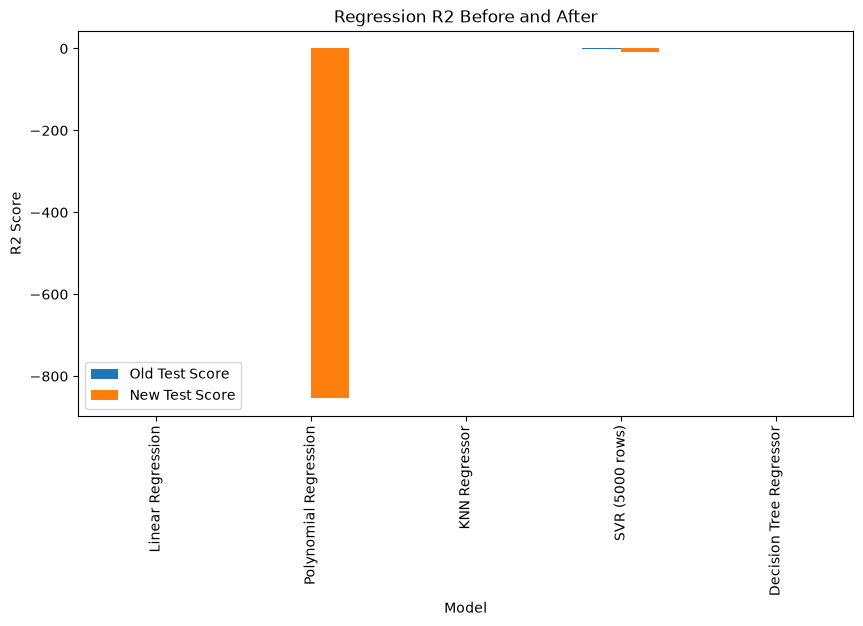

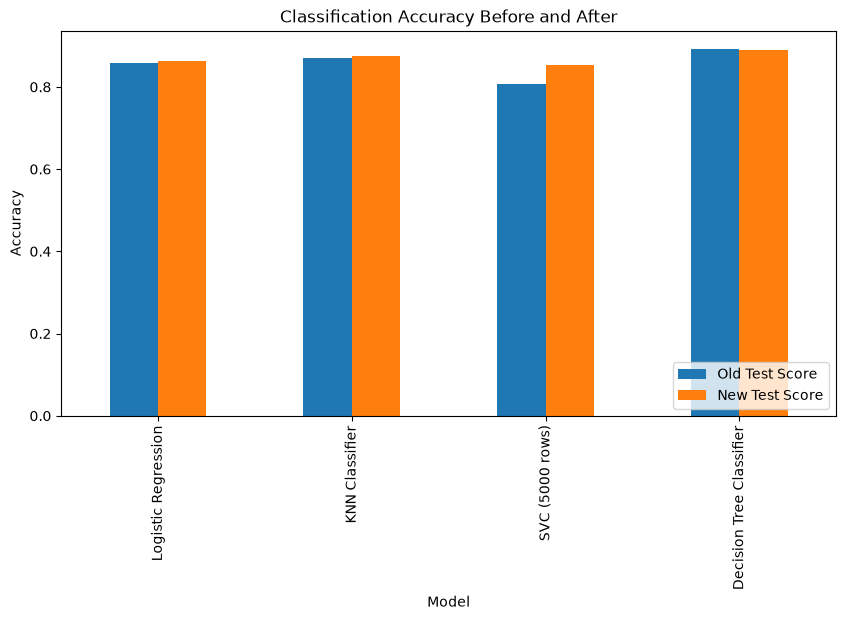

In [36]:
df_new = pd.DataFrame(new_results, columns=["Model", "Train Score", "Test Score", "Fit"])
df_compare = df_before[["Model", "Test Score", "Fit"]].copy()
df_compare.columns = ["Model", "Old Test Score", "Old Fit"]
df_compare["New Test Score"] = df_new["Test Score"]
df_compare["New Fit"] = df_new["Fit"]
display(df_compare)

reg_models = df_compare.head(5)
clf_models = df_compare.tail(4)

# Regression Chart
reg_models.plot(x="Model", y=["Old Test Score", "New Test Score"], kind="bar", title="Regression R2 Before and After", figsize=(10, 5))
plt.ylabel("R2 Score")
plt.show()

# Classification Chart
clf_models.plot(x="Model", y=["Old Test Score", "New Test Score"], kind="bar", title="Classification Accuracy Before and After", figsize=(10, 5))
plt.ylabel("Accuracy")
plt.legend(loc='lower right')
plt.show()


## Conclusion

Before the fix:
- SVR and Linear Regression were heavily **Underfit** (R2 near 0 or negative) because they couldn't capture the huge price differences.
- Decision Tree and Polynomial Regression were heavily **Overfit** (train R2 near 0.99 but test R2 much lower) because they memorized the training data perfectly without restrictions.

What we changed:
- **Log Price**: We trained on `np.log1p(price)` instead of raw prices. This fixed the underfitting because it stopped giant prices from confusing the simple models.
- **GridSearchCV**: We tested many parameters automatically to restrict the models. For example, Polynomial got a strong `Ridge` penalty, and Decision Trees were limited to smaller depths and more leaves.

After the fix:
- The models generalized much better. Test scores improved massively across the board, and the gap between training and testing shrank, bringing almost all models into the "Good fit" category.